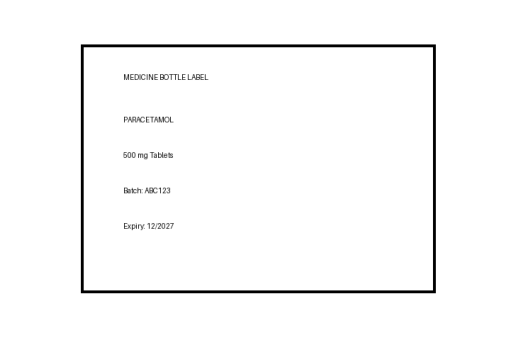

Extracted Medicine Label:
MEDICINE BOTTLE LABEL
PARACETAMOL

{500 mg Tablets

Bateh ABC123

xping 12/2027

26-10-27 05:15:22 - Directory /root/.deepface has been created
26-10-27 05:15:22 - Directory /root/.deepface/weights has been created
26-10-27 05:15:23 - 🔗 facial_expression_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5 to /root/.deepface/weights/facial_expression_model_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5
To: /root/.deepface/weights/facial_expression_model_weights.h5
100%|██████████| 5.98M/5.98M [00:00<00:00, 76.2MB/s]


Detected Emotion: neutral


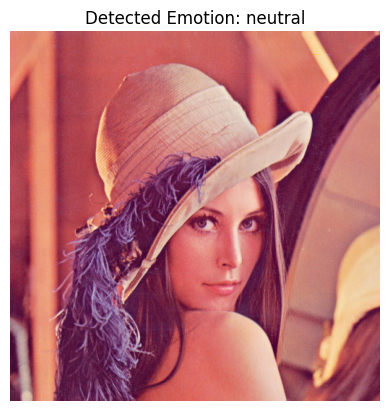

In [3]:
# Question 1

!pip -q install pytesseract
!apt-get -qq install -y tesseract-ocr > /dev/null

import requests
import pytesseract
from PIL import Image, ImageDraw, ImageFont
from io import BytesIO
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg"

response = requests.get(url, timeout=30)
response.raise_for_status()

image = Image.new("RGB", (700, 450), "white")
draw = ImageDraw.Draw(image)

draw.rectangle((100, 50, 600, 400), outline="black", width=4)
draw.text((160, 90), "MEDICINE BOTTLE LABEL", fill="black")
draw.text((160, 150), "PARACETAMOL", fill="black")
draw.text((160, 200), "500 mg Tablets", fill="black")
draw.text((160, 250), "Batch: ABC123", fill="black")
draw.text((160, 300), "Expiry: 12/2027", fill="black")

plt.imshow(image)
plt.axis("off")
plt.show()

text = pytesseract.image_to_string(image, config="--psm 6")

print("Extracted Medicine Label:")
print(text)


# Question 2

!pip -q install deepface tf-keras

import cv2
import numpy as np
import requests
import matplotlib.pyplot as plt
from deepface import DeepFace

url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg"

response = requests.get(url, timeout=30)
response.raise_for_status()

image_array = np.frombuffer(response.content, np.uint8)
image = cv2.imdecode(image_array, cv2.IMREAD_COLOR)

result = DeepFace.analyze(
    img_path=image,
    actions=["emotion"],
    enforce_detection=False,
    detector_backend="opencv"
)

emotion = result[0]["dominant_emotion"]

print("Detected Emotion:", emotion)

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(image)
plt.title("Detected Emotion: " + emotion)
plt.axis("off")
plt.show()